In [1]:
import sys
import os
import pandas as pd

sys.path.append(os.path.abspath('..'))

from quinex_application.quinex_visualisation import QuinexVisualisation
from quinex_application.metadata_visualisation import VisualisationMetadata

In [2]:
visualisation = QuinexVisualisation()
metadata = VisualisationMetadata("../data/quinex/df_quinex_metadata.parquet")

## **Visualise Results**

In [23]:
entity_colors = {
    "Battery": "#8b0000",             # Dunkelrot – Basisfarbe für alle Batterien
    "Lithium-Ion Battery": "#ff0000", # Hellere Variante
    "Lead Acid Battery": "#4E0000",   # Dunklere Variante
    "PV": "#ffd700",                   # Gelb/Gold
    "Wind Turbine": "#1e90ff",        # Himmelblau
    "Coal": "#46250f",                 # Braun
    "Electrolyzer": "#32cd32",         # Grün
    "Hydrogen": "#ff69b4",             # Pink
}


### **Levelized Cost**

In [11]:
cost_lcoh = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_lcoh.xlsx")
cost_lcoe = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_lcoe.xlsx")
cost_capex =pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_capex.xlsx")

#### Select Entities

In [ ]:
cost_lcoh["entity_mapping"].value_counts()

In [12]:
# ---------------------------------------- ENTITY BASE MAPPING -----------------------------------

cost_lcoh = cost_lcoh[cost_lcoh["entity_base_mapping"].isin(['Hydrogen'])]
cost_lcos = cost_lcoe[cost_lcoe["entity_base_mapping"].isin(['Battery'])]
cost_lcoe = cost_lcoe[cost_lcoe["entity_base_mapping"].isin(['PV', 'Wind Turbine'])]
cost_capex = cost_capex[cost_capex["entity_base_mapping"].isin(['PV', 'Wind Turbine', 'Electrolyzer'])]


# ---------------------------------------- ENTITY MAPPING -----------------------------------

# cost_lcoe = cost_lcoe[cost_lcoe["entity_mapping"].isin(['Battery', 'Lithium-Ion Battery', 'Lead Acid Battery'])]
# cost_lcoe["entity_mapping"] = cost_lcoe["entity_mapping"].replace({
#     'Lithium-Ion Battery': 'Lithium Ion',
#     'Lead Acid Battery': 'Lead Acid',
#     'Nickel-Iron Battery': 'Nickel-Iron',
#     'Lithium Iron Phosphate Battery': 'Lithium Iron Phosphate',
# })

# cost_lcoe = cost_lcoe[cost_lcoe["entity_mapping"].isin(['Wind Turbine', 'Offshore Wind Turbine', 'Onshore Wind Turbine'])]
# cost_lcoe["entity_mapping"] = cost_lcoe["entity_mapping"].replace({
#     'Wind Turbine': 'Wind Turbine',
#     'Offshore Wind Turbine': 'Offshore',
#     'Floating Offshore Wind Turbine': 'Floating Offshore',
#     'Onshore Wind Turbine': 'Onshore',
# })

# cost_lcoe = cost_lcoe[cost_lcoe["entity_mapping"].isin(['PVSystem', 'Hybrid PV System', 'Utility-scale PV System'])]
# cost_lcoe["entity_mapping"] = cost_lcoe["entity_mapping"].replace({
#     'PVSystem': 'PV',
#     'Hybrid PV System': 'Hybrid',
#     'Utility-scale PV System': 'Utility-scale',
#     'Rooftop PV System': 'Rooftop',
#     'Photovoltaic-Thermal System (PVT)': 'PVT'
# })

# cost_lcoe = cost_lcoe[cost_lcoe["entity_mapping"].isin(['Hybrid Energy System', 'Hybrid Renewable Energy System (HRES)'])]
# cost_lcoe["entity_mapping"] = cost_lcoe["entity_mapping"].replace({
#     'Hybrid Energy System': 'HES',
#     'Hybrid Renewable Energy System (HRES)' : 'HRES',
# })


# cost_lcoh = cost_lcoh[cost_lcoh["entity_mapping"].isin(['Hydrogen', 'Green Hydrogen'])]
# cost_lcoh["entity_mapping"] = cost_lcoh["entity_mapping"].replace({
#     'Hydrogen': 'Hydrogen',
#     'Blue Hydrogen': 'Blue',
#     'Grey Hydrogen': 'Grey',
#     'Yellow Hydrogen': 'Yellow',
#     'Green Hydrogen': 'Green'
# })

In [ ]:
cost_lcoe = cost_lcoe[cost_lcoe["property_mapping"] == "Levelized Cost"]

In [ ]:
import ast  # sicherer als json für Python-Style dicts

# Spalte konvertieren
cost_lcoe["classification_dict"] = cost_lcoe["classification"].apply(ast.literal_eval)

# Jetzt filtern nach system == "real_world"
cost_lcoe = cost_lcoe[
    cost_lcoe["classification_dict"].apply(lambda x: x.get("system") == "real_world")
]

In [ ]:
len(cost_capex)

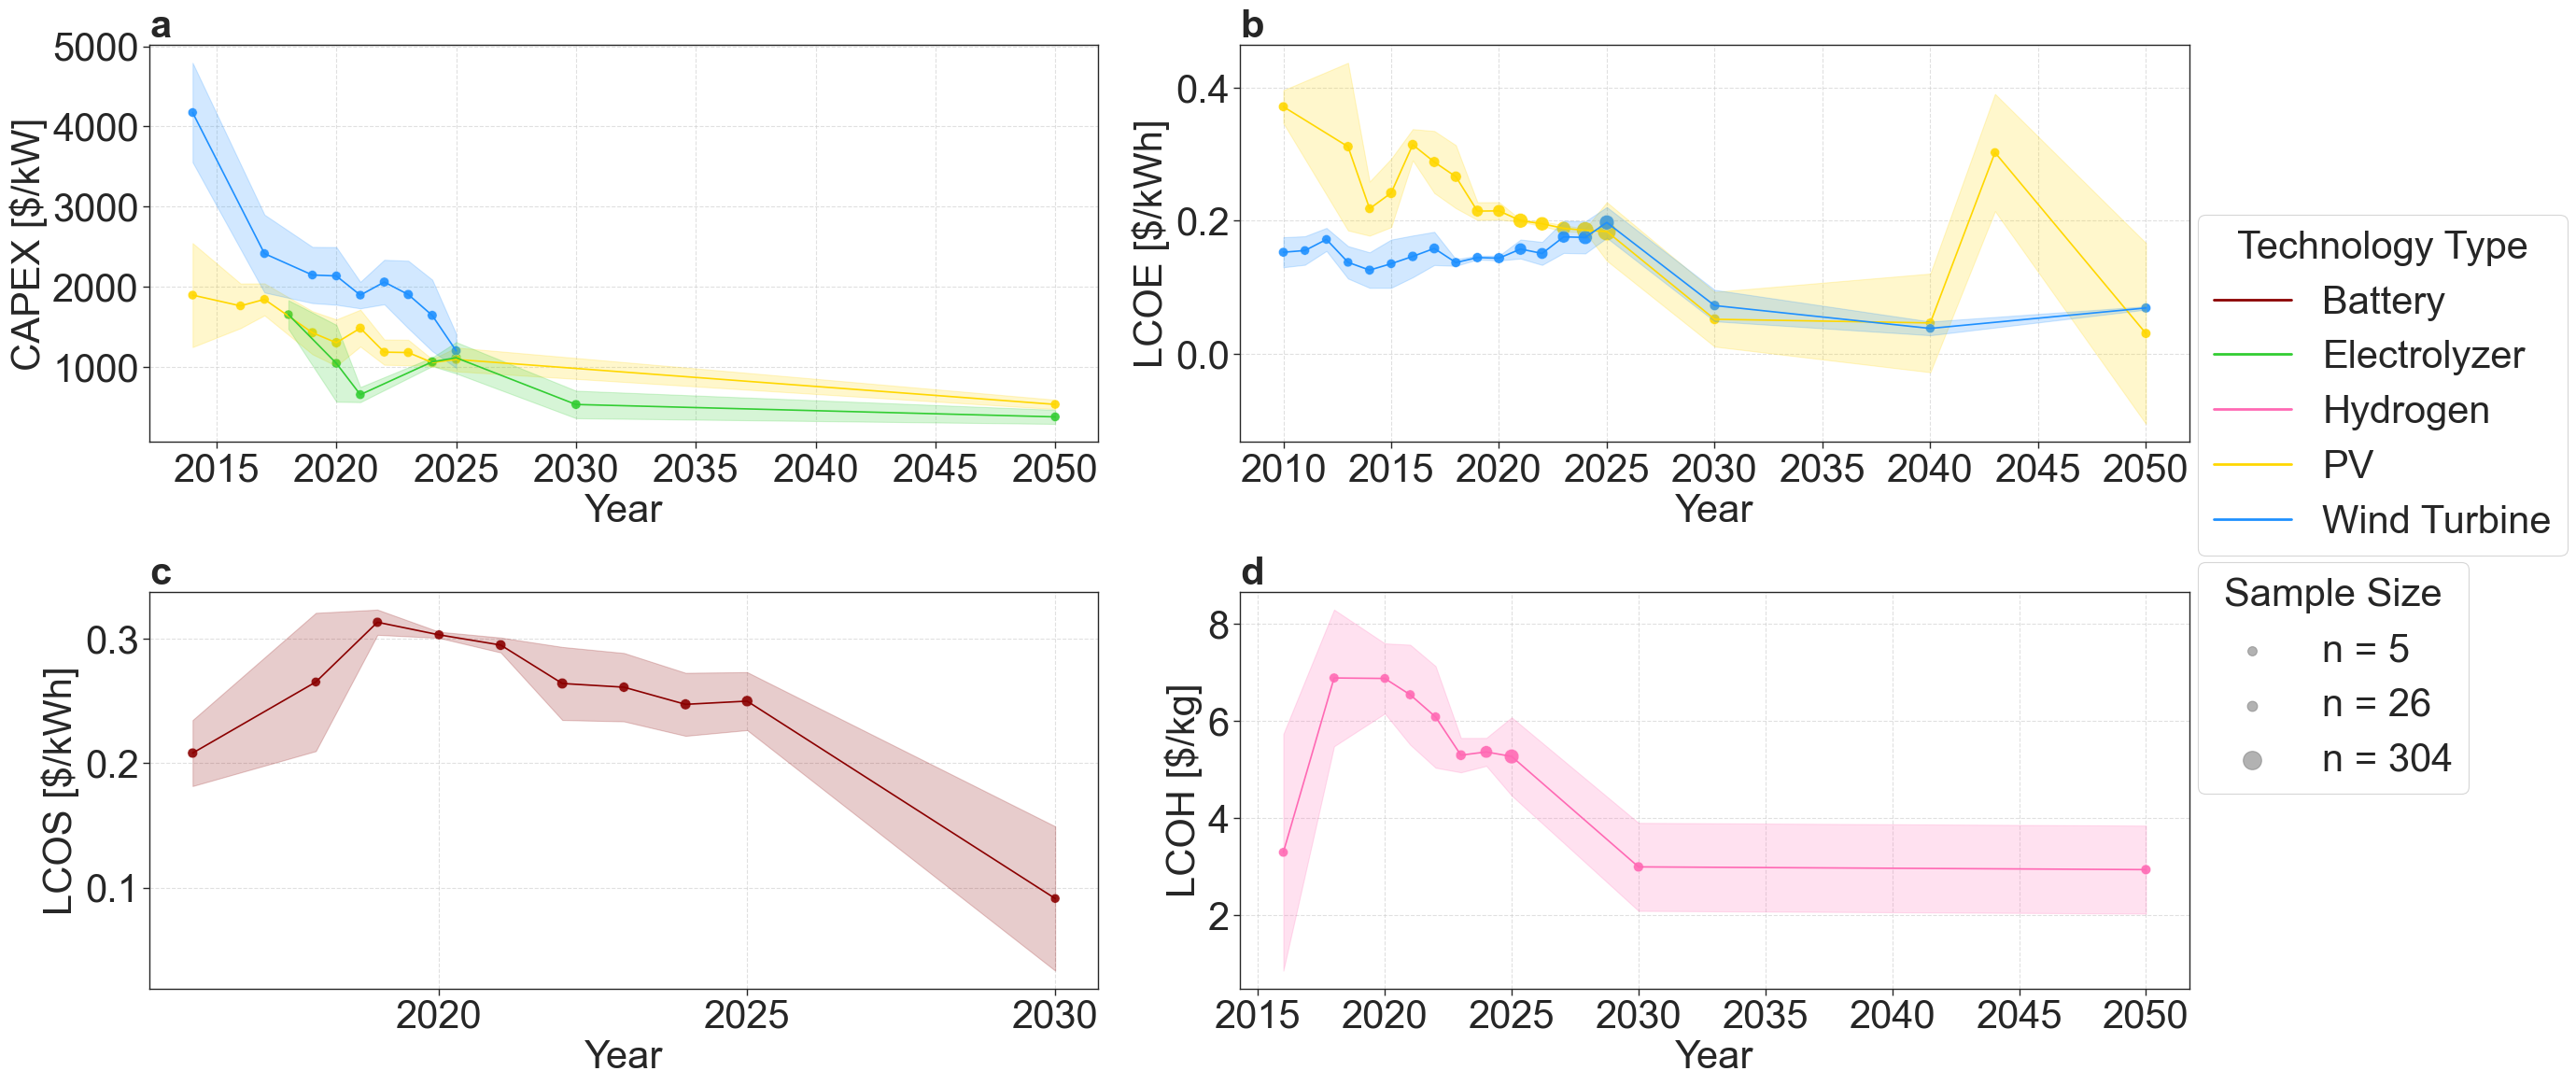

In [27]:
data = [
    {
    'df': cost_capex,
    'entity_col': 'entity_base_mapping',
    'value_col': 'value_converted',
    'ylabel': 'CAPEX [$/kW]', 
    'title': 'a'
    },
    {
    'df': cost_lcoe,
    'entity_col': 'entity_base_mapping',
    'value_col': 'value_converted',
    'ylabel': 'LCOE [$/kWh]', 
    'title': 'b'
    },
    {
    'df': cost_lcos,
    'entity_col': 'entity_base_mapping',
    'value_col': 'value_converted',
    'ylabel': 'LCOS [$/kWh]', 
    'title': 'c'
    },
    {
    'df': cost_lcoh,
    'entity_col': 'entity_base_mapping',
    'value_col': 'value_converted',
    'ylabel': 'LCOH [$/kg]', 
    'title': 'd'
    }
]

fig = visualisation.plot_multiple_properties_over_time(
    data_list=data,
    legend_title = 'Technology Type',
    color_dict=entity_colors,
    figsize=(24,12),
    legend_position=(0.98,0.81),
    legend_size_position=(0.98,0.5),
    central_tendency="moving average",
    error_type="se",
    error_display="shade",
    font_size=30
    )

fig.savefig("../data/figures/results/cost/technologies_costs.pdf", bbox_inches='tight')

### **Lifetime**

In [20]:
df = pd.read_parquet("../data/visualisation_files/df_technologies.parquet")
lifetime = df[df["property_mapping"] == "Lifetime"]
lifetime = lifetime[lifetime['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/YR'
)]
lifetime["unit_normalized"].value_counts()

unit_normalized
[{'exponent': 1.0, 'text': 'years', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]    2945
[{'exponent': 1.0, 'text': 'year', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]      172
[{'exponent': 1.0, 'text': 'yr', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]         16
[{'exponent': 1.0, 'text': 'yrs', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]        11
[{'exponent': 1.0, 'text': 'a', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]           3
[{'exponent': 1.0, 'text': 'Years', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]       3
[{'exponent': 1.0, 'text': 'y', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]           3
Name: count, dtype: int64

#### Select Entities

In [ ]:
lifetime["entity_mapping"].value_counts()

In [ ]:
#lifetime = lifetime[lifetime["entity_base_mapping"].isin(['PV', 'Battery', 'Wind Turbine', 'Electrolyzer', 'Coal'])]
lifetime = lifetime[lifetime["entity_base_mapping"].isin(['Battery'])]
lifetime = lifetime[lifetime["entity_mapping"] != 'Battery']
# lifetime["entity_mapping"].value_counts()

In [ ]:
data = [
    {
    'df': lifetime,
    'entity_col': 'entity_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Lifetime [Years]', 
    }
]


fig = visualisation.plot_multiple_properties_over_time(
    data_list = data,
    legend_title = 'Technology Type',
    figsize=(24,6),
    legend_position=(0.984,0.92),
    legend_size_position=(0.984,0.5),
    central_tendency="moving average",
    error_type="se",
    error_display="shade",
    font_size=24
    )

fig.show()
#fig.savefig("../data/figures/results/lifetime/technologies_lifetime.pdf", bbox_inches='tight')

#### **Efficiency**

In [21]:
df = pd.read_parquet("../data/visualisation_files/df_technologies.parquet")
efficiency = df[df["property_mapping"] == "Efficiency"]
efficiency = efficiency[efficiency['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/PERCENT'
)]
efficiency["unit_normalized"].value_counts()

unit_normalized
[{'exponent': 1.0, 'text': '%', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]          9537
[{'exponent': 1.0, 'text': 'percent', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]      41
Name: count, dtype: int64

#### Select Entities

In [ ]:
efficiency["entity_base_mapping"].value_counts()

In [ ]:
#efficiency = efficiency[efficiency["entity_base_mapping"].isin(['PV', 'Battery', 'Wind Turbine', 'Electrolyzer', 'Coal'])]
efficiency = efficiency[efficiency["entity_base_mapping"].isin(['Battery'])]
efficiency = efficiency[efficiency["entity_mapping"] != 'Battery']

In [ ]:
efficiency["property_mapping"].value_counts()

C:\Users\m.gorres\AppData\Local\Temp\ipykernel_12112\2279414110.py:46: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


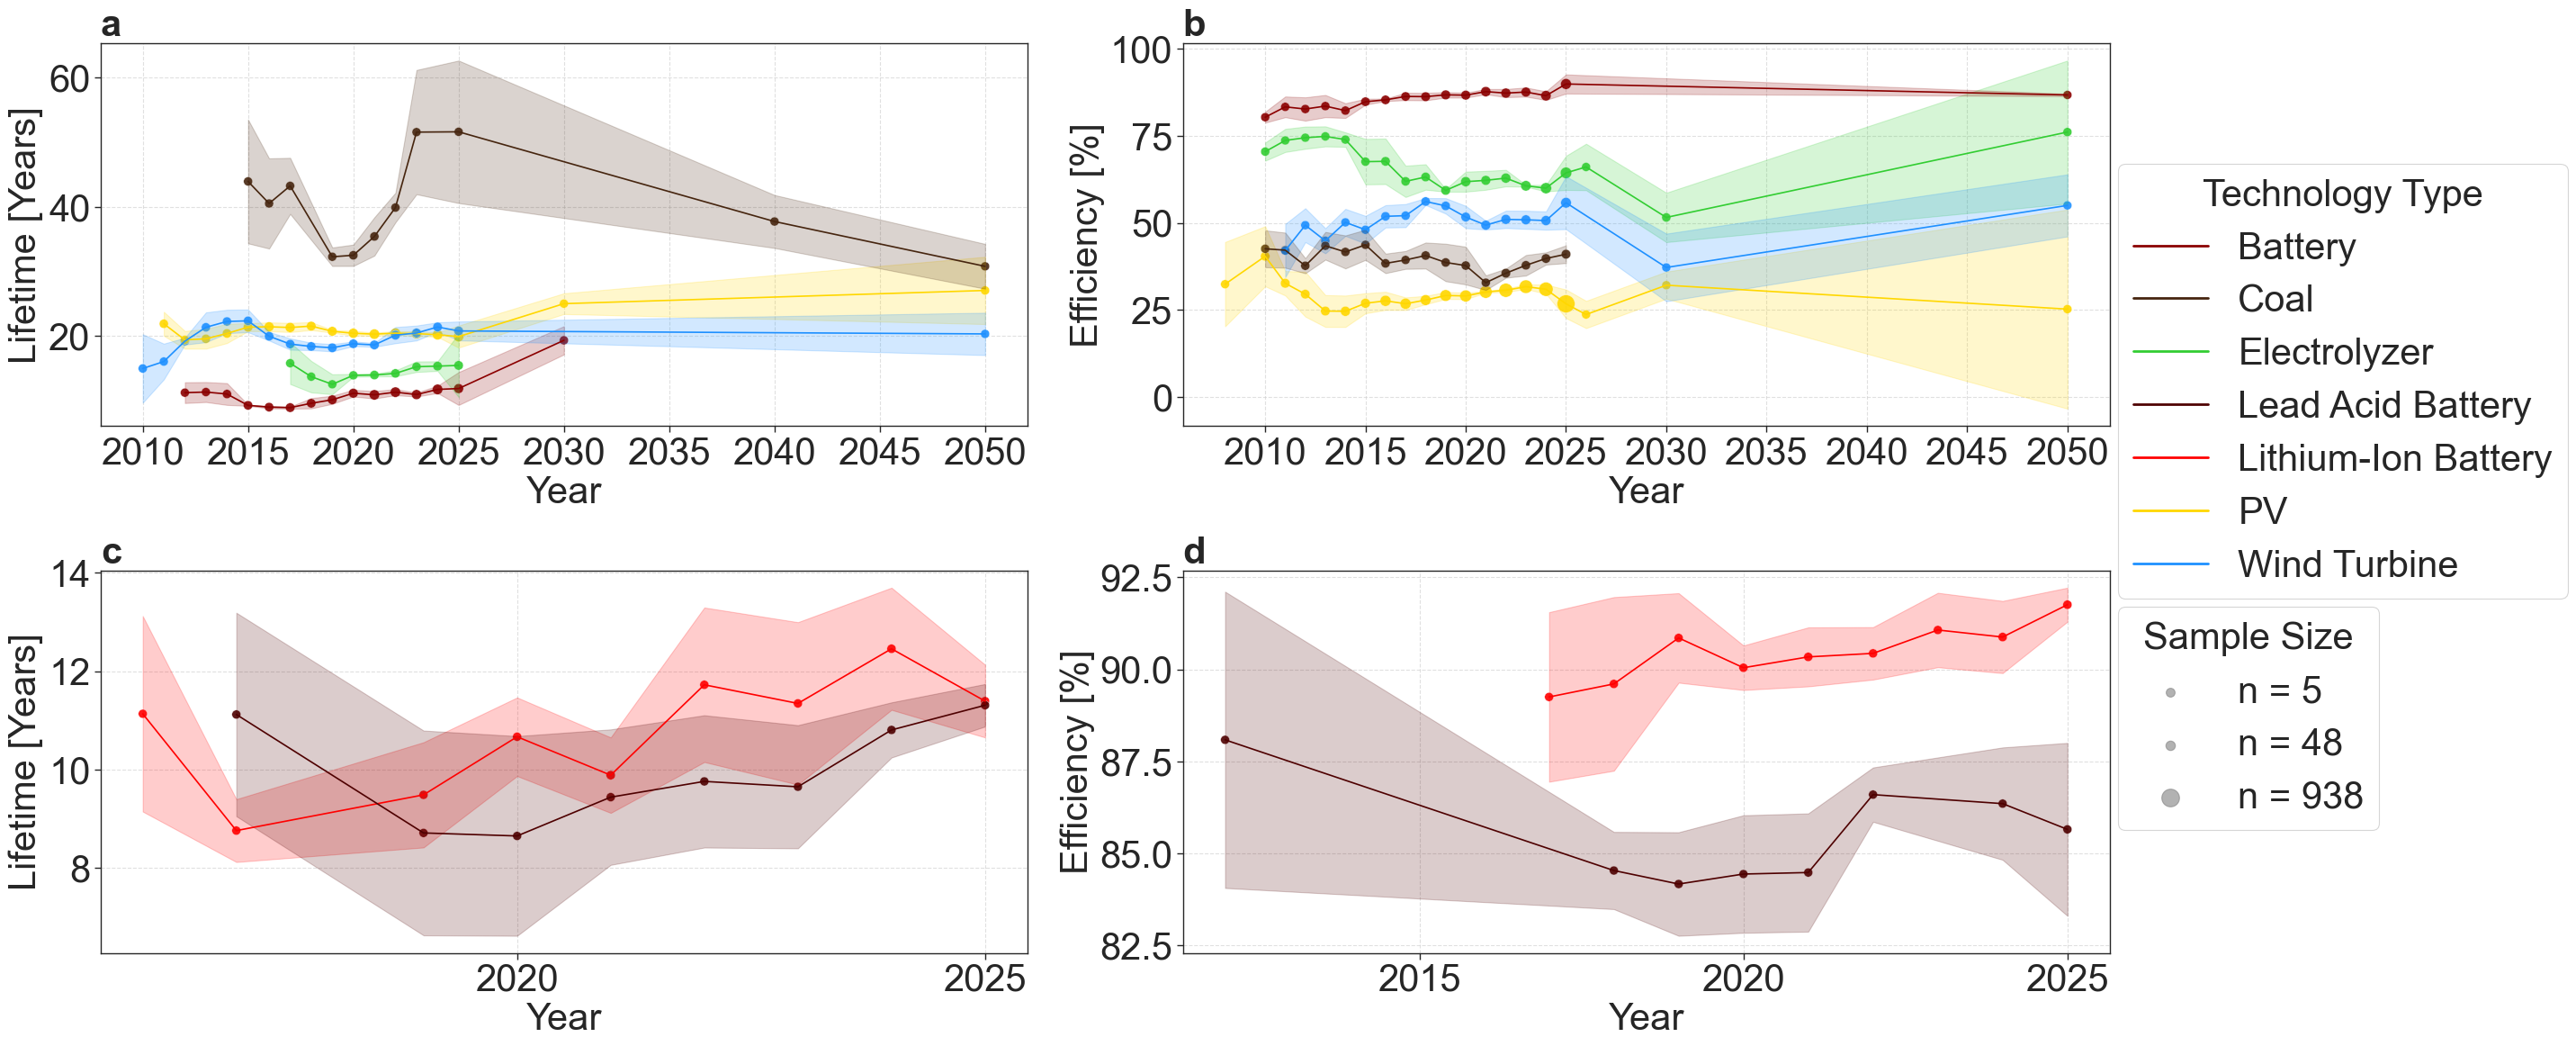

In [26]:
data = [
    {
    'df': lifetime[lifetime["entity_base_mapping"].isin(['PV', 'Battery', 'Wind Turbine', 'Electrolyzer', 'Coal'])],
    'entity_col': 'entity_base_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Lifetime [Years]',
     'title': 'a'
    },
    {
    'df': efficiency[efficiency["entity_base_mapping"].isin(['PV', 'Battery', 'Wind Turbine', 'Electrolyzer', 'Coal'])],
    'entity_col': 'entity_base_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Efficiency [%]', 
    'title': 'b'
    },
    {
    'df': lifetime[lifetime["entity_mapping"].isin(['Lithium-Ion Battery', 'Lead Acid Battery'])],
    'entity_col': 'entity_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Lifetime [Years]',
     'title': 'c'
    },
    {
    'df': efficiency[efficiency["entity_mapping"].isin(['Lithium-Ion Battery', 'Lead Acid Battery'])],
    'entity_col': 'entity_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Efficiency [%]', 
    'title': 'd'
    },
]


fig = visualisation.plot_multiple_properties_over_time(
    data_list = data,
    legend_title = 'Technology Type',
    color_dict=entity_colors,
    figsize=(24,12),
    legend_position=(0.98,0.85),
    legend_size_position=(0.98,0.44),
    central_tendency="moving average",
    error_type="se",
    error_display="shade",
    font_size=30
    )

fig.show()
fig.savefig("../data/figures/results/technologies_properties.pdf", bbox_inches='tight')

#### **Capacity**

In [ ]:
capacity = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_capacity_mw.xlsx")

In [ ]:
fig = visualisation.plot_top_values(capacity, column="entity", top_n=20, ignore_empty=True, figsize=(6,6), title="Top 20 Entities")

#### Select Entities

In [ ]:
#capacity = capacity[capacity["entity_base_mapping"].isin(['pv', 'battery', 'wind turbine', 'electrolyzer'])]

#capacity = capacity[capacity["entity_mapping"].isin(['PVSystem', 'Wind Turbine'])]

# capacity = capacity[capacity["entity_mapping"].isin(['Offshore Wind Turbine', 'Floating Offshore Wind Turbine', 'Onshore Wind Turbine'])]
# capacity["entity_mapping"] = capacity["entity_mapping"].replace({
#     'Offshore Wind Turbine': 'Offshore',
#     'Floating Offshore Wind Turbine': 'Floating Offshore',
#     'Onshore Wind Turbine': 'Onshore'
# })

capacity = capacity[capacity["entity_mapping"].isin(['Hybrid PV System', 'Utility-scale PV System', 'Rooftop PV System', 'Photovoltaic-Thermal System (PVT)'])]
capacity["entity_mapping"] = capacity["entity_mapping"].replace({
    'Hybrid PV System': 'Hybrid PV',
    'Utility-scale PV System': 'Utility-scale PV',
    'Rooftop PV System': 'Rooftop PV',
    'Photovoltaic-Thermal System (PVT)': 'PVT'
})

capacity = capacity[capacity["property"].isin(['installed capacity'])]

In [ ]:
fig = visualisation.plot_properties_over_time(
    df = capacity,
    entity_col = 'entity_base_mapping',
    value_col = 'value_converted',
    ylabel = 'Installed Capacity [GW]', 
    title = 'Levelized Cost of Wind Turbine Over Time',
    legend_title = 'Technology Type',
    figsize=(12,6),
    legend_position=(0.075,0.965),
    legend_size_position=(0.265,0.965),
    central_tendency="moving average",
    #palette = farbe_hydrogen,
    error_type="se",
    error_display="shade"
    )

fig.show()
fig.savefig("../data/figures/results/capacity/technologies_capacity.pdf", bbox_inches='tight')

#### **Emission**

In [ ]:
df = pd.read_parquet("../data/visualisation_files/df_technologies.parquet")
emission = df[df["property_mapping"] == "CO2 emission"]
# emission = emission[emission['unit_normalized'].apply(
#     lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/PERCENT'
# )]
emission["unit_normalized"].value_counts().head(20)

#### Select Entities

In [ ]:
emission["entity_base_mapping"].value_counts()

In [ ]:
emission = emission[emission["entity_base_mapping"].isin(['PV', 'Battery', 'Wind Turbine', 'Electrolyzer'])]
emission = emission[emission["entity_base_mapping"].isin(['Battery'])]
emission = emission[emission["entity_mapping"] != 'Battery']

In [ ]:
data = [
    # {
    # 'df': lifetime,
    # 'entity_col': 'entity_base_mapping',
    # 'value_col': 'value_normalized',
    # 'ylabel': 'Lifetime [Years]', 
    # },
    {
    'df': emission,
    'entity_col': 'entity_base_mapping',
    'value_col': 'value_normalized',
    'ylabel': 'Emission [%]', 
    },
    # {
    # 'df': cost_lcoe,
    # 'entity_col': 'entity_base_mapping',
    # 'value_col': 'value_converted',
    # 'ylabel': 'Levelized Cost [USD/kWh]', 
    # }
]


fig = visualisation.plot_multiple_properties_over_time(
    data_list = data,
    legend_title = 'Technology Type',
    figsize=(24,6),
    legend_position=(0.984,0.92),
    legend_size_position=(0.984,0.66),
    central_tendency="moving average",
    error_type="se",
    error_display="shade",
    font_size=24
    )

fig.show()
#fig.savefig("../data/figures/results/efficiency/battery_efficiency.pdf", bbox_inches='tight')